# 02 — Robustness and phase planes (checklist 1.4–1.5)

Post-baseline checks for the **validated untreated 7D Plant–Kim / Canavier** model.

- Reuses `src/plant_kim_model.py` (no equation/parameter changes)
- Solver: PyDSTool **VODE only**
- Scope: initial-condition robustness, numerical-tolerance robustness, post-transient $V$–gate phase planes
- Out of scope: drugs, sweeps, AUTO, SciPy ODE solvers, checklist edits

Reference late attractor from notebook 01: ~4 spikes/burst, period ~9 s, $V \approx [-52,+28]$ mV after discarding ~10 s transient.


## 1. Purpose and scope

Establish that untreated bursting is a robust attracting regime (not an artefact of one IC, tolerance, or transient), then visualise the post-transient orbit in $(V, X_\bullet)$ projections with emphasis on $(V, X_P)$.


## 2. Imports and environment confirmation


In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import matplotlib.pyplot as plt

from src.plant_kim_model import (
    BASELINE_PARS,
    STATE_VARS,
    DEFAULT_ALGPARAMS,
    steady_state_ics,
    build_vode_system,
    simulate,
)

FIGDIR = REPO_ROOT / 'outputs' / 'figures' / 'robustness_phase_planes'
FIGDIR.mkdir(parents=True, exist_ok=True)

print('executable:', sys.executable)
print('version:', sys.version.split()[0])
assert '.venv' in sys.executable.replace('\\', '/'), 'Use the project .venv interpreter / pydstool kernel'
print('FIGDIR:', FIGDIR)
print('DEFAULT_ALGPARAMS:', DEFAULT_ALGPARAMS)
print('I_ext =', BASELINE_PARS['I_ext'], 'I_ep =', BASELINE_PARS['I_ep'])


executable: /Users/calvinlai/Desktop/MATH3888/.venv/bin/python
version: 3.9.20
FIGDIR: /Users/calvinlai/Desktop/MATH3888/outputs/figures/robustness_phase_planes
DEFAULT_ALGPARAMS: {'rtol': 1e-06, 'atol': 1e-08, 'stiff': True, 'init_step': 0.1, 'max_step': 1.0}
I_ext = 0.0 I_ep = -0.22


## 3. Validated model API

Import-only reuse of the Canavier-corrected implementation. Tolerance overrides use a **full** `algparams` dict (`dict(DEFAULT_ALGPARAMS)` then override), because a partial dict replaces rather than merges.


In [2]:
T_END = 40000.0   # ms
DT = 0.5          # ms sample
T_CUT = 10000.0   # ms: discard initial transient (matches notebook 01)
SPIKE_THR = -20.0 # mV upward-crossing threshold
BURST_GAP = 1500.0  # ms: ISI > this starts a new burst


def make_algparams(**overrides):
    cfg = dict(DEFAULT_ALGPARAMS)
    cfg.update(overrides)
    return cfg


def run_sim(run_id, ics, algparams=None, trajname=None):
    # Integrate untreated 7D VODE; return dict of numpy arrays.
    name = trajname or run_id
    ode = build_vode_system(ics=ics, algparams=algparams, name='PK_' + run_id)
    print('Computing', run_id, '...', flush=True)
    pts = simulate(ode, tdata=[0.0, T_END], dt=DT, trajname=name)
    data = {k: np.asarray(pts[k], dtype=float) for k in ['t', *STATE_VARS]}
    print('  done: V in [{:.3g}, {:.3g}] mV'.format(data['V'].min(), data['V'].max()), flush=True)
    return data


def group_bursts(tspike, gap=BURST_GAP):
    if len(tspike) == 0:
        return []
    groups = [[tspike[0]]]
    for i in range(1, len(tspike)):
        if tspike[i] - tspike[i - 1] > gap:
            groups.append([tspike[i]])
        else:
            groups[-1].append(tspike[i])
    return groups


def analyse_post_transient(data, run_id, t_cut=T_CUT):
    t = data['t']
    V = data['V']
    mask = t >= t_cut
    t2, V2 = t[mask], V[mask]
    XI2 = data['X_I'][mask]

    cross = np.where((V2[:-1] <= SPIKE_THR) & (V2[1:] > SPIKE_THR))[0]
    tspike = t2[cross]
    groups = group_bursts(tspike)
    sizes = [len(g) for g in groups]
    onsets = [g[0] for g in groups]
    periods = np.diff(onsets) if len(onsets) >= 2 else np.array([])

    regime = 'bursting' if (len(groups) >= 2 and V2.max() > 0 and all(s >= 1 for s in sizes)) else 'other'

    return {
        'run_id': run_id,
        'regime': regime,
        'V_min': float(V2.min()),
        'V_max': float(V2.max()),
        'n_spikes': int(len(tspike)),
        'n_bursts': int(len(groups)),
        'spikes_per_burst': sizes,
        'median_spikes_per_burst': float(np.median(sizes)) if sizes else float('nan'),
        'period_s_median': float(np.median(periods) / 1000.0) if len(periods) else float('nan'),
        'periods_s': [float(p / 1000.0) for p in periods],
        'X_I_max': float(XI2.max()),
    }


## 4. Baseline reference simulation (`ref_V50`)

Same IC strategy as notebook 01: $V_0=-50$ mV with gates at steady state; default VODE `algparams`.


In [3]:
ics_ref = steady_state_ics(-50.0)
print('ref ICs:', {k: round(v, 6) for k, v in ics_ref.items()})
traj = {}
traj['ref_V50'] = run_sim('ref_V50', ics=ics_ref, algparams=None)


ref ICs: {'V': -50.0, 'X_K': 0.046642, 'X_A': 0.401312, 'Y_A': 0.5, 'X_P': 0.109097, 'X_I': 0.017488, 'Y_I': 0.902731}
Computing ref_V50 ...


  done: V in [-52, 27.7] mV


## 5. Transient cutoff and analysis helpers

- Analysis window: $t \ge T_{\mathrm{cut}} = 10$ s
- Spike: upward crossing of $V=-20$ mV (APs reach $\sim +27$ mV; slow envelope stays $\lesssim -30$ mV)
- Burst grouping: ISI $> 1.5$ s starts a new burst
- Period: median inter-onset interval of post-transient bursts


In [4]:
ref_metrics = analyse_post_transient(traj['ref_V50'], 'ref_V50')
print(ref_metrics)


{'run_id': 'ref_V50', 'regime': 'bursting', 'V_min': -51.623350363172484, 'V_max': 27.487073908164597, 'n_spikes': 12, 'n_bursts': 3, 'spikes_per_burst': [4, 4, 4], 'median_spikes_per_burst': 4.0, 'period_s_median': 9.043472608681522, 'periods_s': [9.06042265105663, 9.026522566306415], 'X_I_max': 0.9916032056022661}


## 6. Initial-condition robustness

Physiological ICs only: steady-state gates at $V_0\in\{-60,-50,-40\}$, plus a modest $X_P$ offset ($+0.15$, clipped to $[0,1]$) from the baseline IC to probe the slow manifold phase.


Computing ic_V60 ...


  done: V in [-60, 27.8] mV


Computing ic_V40 ...


  done: V in [-56.1, 27.5] mV


ic_XP X_P = 0.25909682119561295
Computing ic_XP ...


  done: V in [-52, 27.6] mV


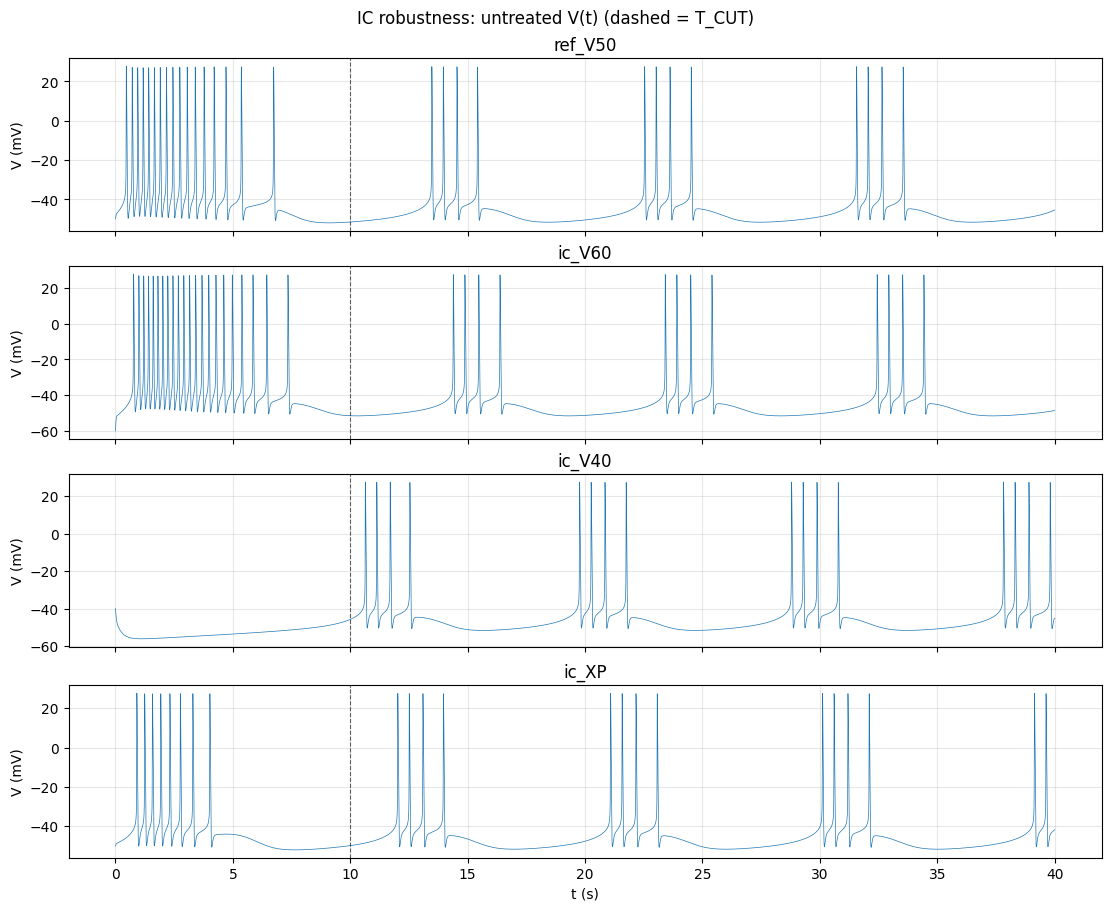

In [5]:
for V0, rid in [(-60.0, 'ic_V60'), (-40.0, 'ic_V40')]:
    traj[rid] = run_sim(rid, ics=steady_state_ics(V0), algparams=None)

ics_xp = steady_state_ics(-50.0)
ics_xp['X_P'] = float(np.clip(ics_xp['X_P'] + 0.15, 0.0, 1.0))
print('ic_XP X_P =', ics_xp['X_P'])
traj['ic_XP'] = run_sim('ic_XP', ics=ics_xp, algparams=None)

ic_ids = ['ref_V50', 'ic_V60', 'ic_V40', 'ic_XP']
fig, axes = plt.subplots(len(ic_ids), 1, figsize=(11, 9), sharex=True, constrained_layout=True)
for ax, rid in zip(axes, ic_ids):
    d = traj[rid]
    ax.plot(d['t'] / 1000.0, d['V'], lw=0.5)
    ax.axvline(T_CUT / 1000.0, color='k', ls='--', lw=0.8, alpha=0.6)
    ax.set_ylabel('V (mV)')
    ax.set_title(rid)
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel('t (s)')
fig.suptitle('IC robustness: untreated V(t) (dashed = T_CUT)')
fig.savefig(FIGDIR / 'robustness_V_traces_ics.png', dpi=150)
plt.show()


## 7. Numerical-tolerance robustness

Same ICs as reference. Compare baseline / tighter / looser VODE settings (complete `algparams` dicts).


tight: {'rtol': 1e-07, 'atol': 1e-09, 'stiff': True, 'init_step': 0.1, 'max_step': 0.5}
loose: {'rtol': 1e-05, 'atol': 1e-07, 'stiff': True, 'init_step': 0.1, 'max_step': 2.0}
Computing tol_tight ...


  done: V in [-52, 27.7] mV


Computing tol_loose ...


  done: V in [-51.9, 27.7] mV


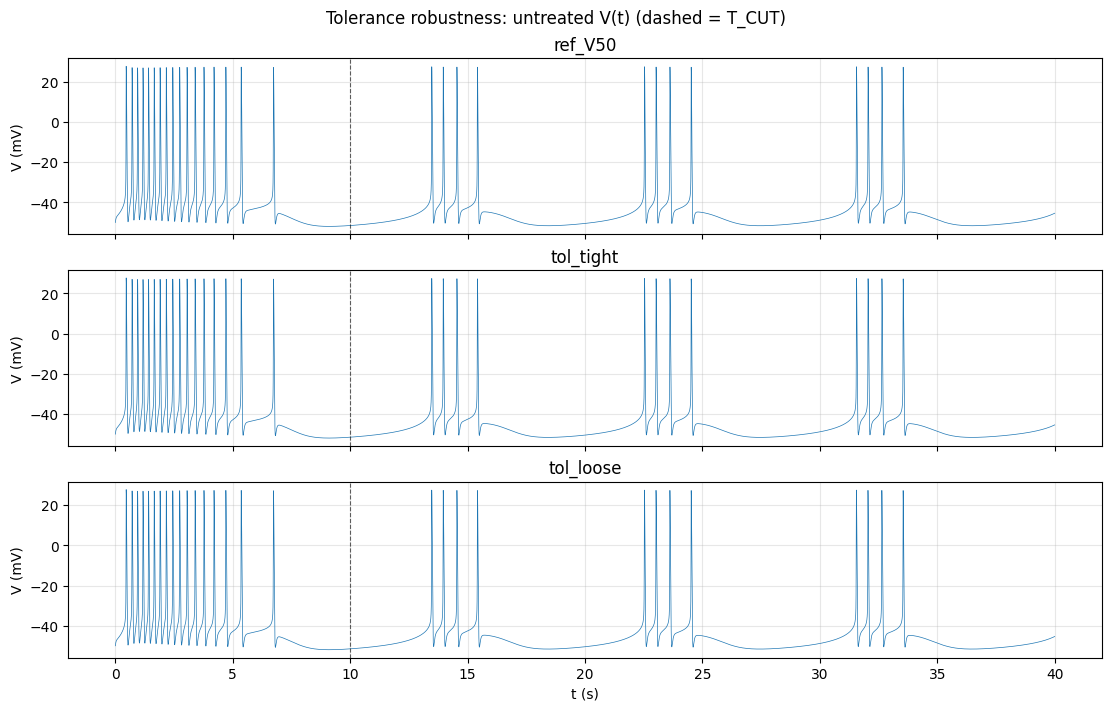

In [6]:
alg_tight = make_algparams(rtol=1e-7, atol=1e-9, max_step=0.5)
alg_loose = make_algparams(rtol=1e-5, atol=1e-7, max_step=2.0)
print('tight:', alg_tight)
print('loose:', alg_loose)

traj['tol_tight'] = run_sim('tol_tight', ics=ics_ref, algparams=alg_tight)
traj['tol_loose'] = run_sim('tol_loose', ics=ics_ref, algparams=alg_loose)

tol_ids = ['ref_V50', 'tol_tight', 'tol_loose']
fig, axes = plt.subplots(len(tol_ids), 1, figsize=(11, 7), sharex=True, constrained_layout=True)
for ax, rid in zip(axes, tol_ids):
    d = traj[rid]
    ax.plot(d['t'] / 1000.0, d['V'], lw=0.5)
    ax.axvline(T_CUT / 1000.0, color='k', ls='--', lw=0.8, alpha=0.6)
    ax.set_ylabel('V (mV)')
    ax.set_title(rid)
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel('t (s)')
fig.suptitle('Tolerance robustness: untreated V(t) (dashed = T_CUT)')
fig.savefig(FIGDIR / 'robustness_V_traces_tol.png', dpi=150)
plt.show()


## 8–9. Post-transient diagnostics and summary table


In [7]:
all_ids = ['ref_V50', 'ic_V60', 'ic_V40', 'ic_XP', 'tol_tight', 'tol_loose']
rows = [analyse_post_transient(traj[rid], rid) for rid in all_ids]

hdr = '{:12s} {:10s} {:>8s} {:>8s} {:>5s} {:>5s} {:>7s} {:>6s} {:>8s} {}'.format(
    'run_id', 'regime', 'Vmin', 'Vmax', 'nspk', 'nbur', 'med_spk', 'T_s', 'XI_max', 'spikes/burst')
print(hdr)
for r in rows:
    print('{:12s} {:10s} {:8.2f} {:8.2f} {:5d} {:5d} {:7.1f} {:6.2f} {:8.3f} {}'.format(
        r['run_id'], r['regime'], r['V_min'], r['V_max'], r['n_spikes'], r['n_bursts'],
        r['median_spikes_per_burst'], r['period_s_median'], r['X_I_max'], r['spikes_per_burst']))

csv_path = FIGDIR / 'robustness_summary.csv'
with open(csv_path, 'w') as f:
    f.write('run_id,regime,V_min,V_max,n_spikes,n_bursts,median_spikes_per_burst,period_s_median,X_I_max,spikes_per_burst\n')
    for r in rows:
        spb = ';'.join(str(s) for s in r['spikes_per_burst'])
        f.write('{},{},{:.6g},{:.6g},{},{},{:.6g},{:.6g},{:.6g},"{}"\n'.format(
            r['run_id'], r['regime'], r['V_min'], r['V_max'], r['n_spikes'], r['n_bursts'],
            r['median_spikes_per_burst'], r['period_s_median'], r['X_I_max'], spb))
print('Saved', csv_path)


run_id       regime         Vmin     Vmax  nspk  nbur med_spk    T_s   XI_max spikes/burst
ref_V50      bursting     -51.62    27.49    12     3     4.0   9.04    0.992 [4, 4, 4]
ic_V60       bursting     -51.62    27.49    12     3     4.0   9.03    0.992 [4, 4, 4]
ic_V40       bursting     -51.64    27.49    16     4     4.0   9.03    0.992 [4, 4, 4, 4]
ic_XP        bursting     -51.62    27.49    14     4     4.0   9.03    0.992 [4, 4, 4, 2]
tol_tight    bursting     -51.62    27.49    12     3     4.0   9.04    0.992 [4, 4, 4]
tol_loose    bursting     -51.62    27.49    12     3     4.0   9.04    0.992 [4, 4, 4]
Saved /Users/calvinlai/Desktop/MATH3888/outputs/figures/robustness_phase_planes/robustness_summary.csv


## 10. Interpretation of robustness results


In [8]:
ref = rows[0]
ok = True
notes = []
for r in rows:
    if r['regime'] != 'bursting':
        ok = False
        notes.append('{}: regime={}'.format(r['run_id'], r['regime']))
    if abs(r['median_spikes_per_burst'] - ref['median_spikes_per_burst']) > 0.5:
        ok = False
        notes.append('{}: median spikes {} vs ref {}'.format(
            r['run_id'], r['median_spikes_per_burst'], ref['median_spikes_per_burst']))
    if np.isfinite(r['period_s_median']) and abs(r['period_s_median'] - ref['period_s_median']) > 2.0:
        ok = False
        notes.append('{}: period {:.2f}s vs ref {:.2f}s'.format(
            r['run_id'], r['period_s_median'], ref['period_s_median']))

if ok:
    print('PASS: sensible ICs and reasonable VODE tolerances converge to the same')
    print('post-transient bursting regime (similar period, spike count, voltage range).')
    print('Reference: ~{:.0f} spikes/burst, period ~{:.1f} s, V in [{:.1f}, {:.1f}] mV.'.format(
        ref['median_spikes_per_burst'], ref['period_s_median'], ref['V_min'], ref['V_max']))
else:
    print('DISAGREEMENT / FAIL against rough robustness criteria:')
    for n in notes:
        print(' -', n)


PASS: sensible ICs and reasonable VODE tolerances converge to the same
post-transient bursting regime (similar period, spike count, voltage range).
Reference: ~4 spikes/burst, period ~9.0 s, V in [-51.6, 27.5] mV.


## 11. Six $V$–state phase-plane projections

Post-transient only ($t \ge T_{\mathrm{cut}}$), using the reference trajectory `ref_V50`.


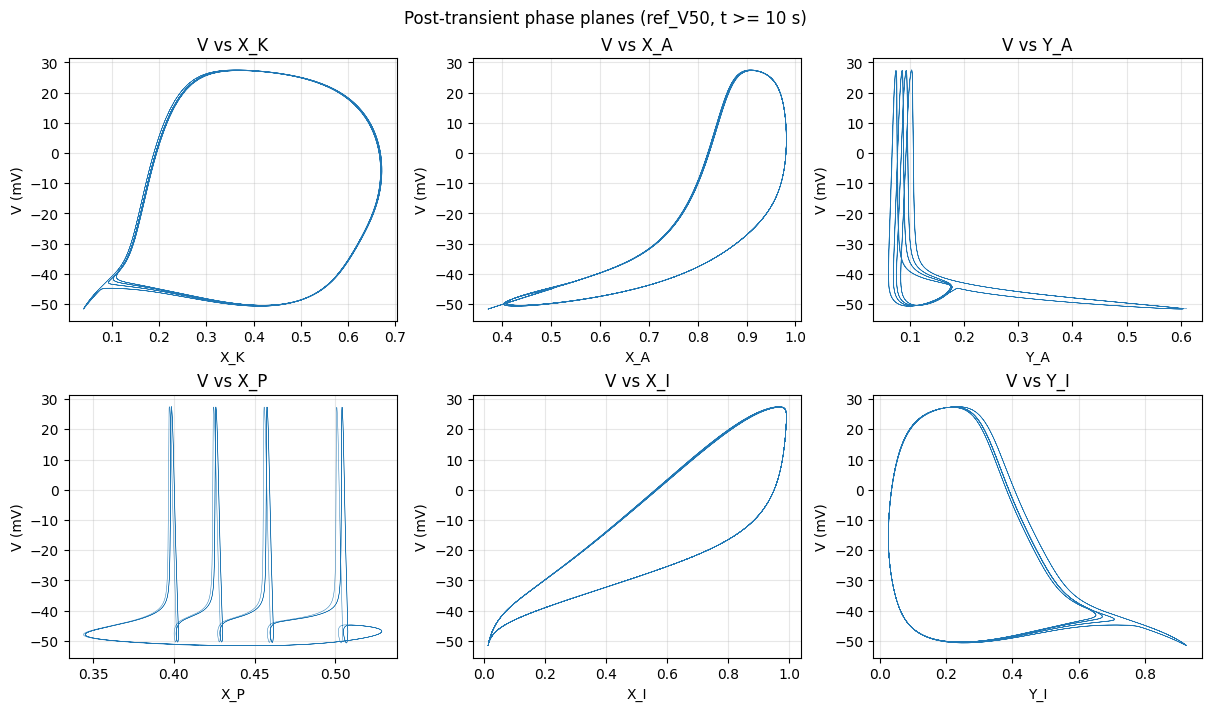

In [9]:
d = traj['ref_V50']
m = d['t'] >= T_CUT
V = d['V'][m]
gates = [
    ('X_K', d['X_K'][m]),
    ('X_A', d['X_A'][m]),
    ('Y_A', d['Y_A'][m]),
    ('X_P', d['X_P'][m]),
    ('X_I', d['X_I'][m]),
    ('Y_I', d['Y_I'][m]),
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
for ax, (name, g) in zip(axes.ravel(), gates):
    ax.plot(g, V, lw=0.35)
    ax.set_xlabel(name)
    ax.set_ylabel('V (mV)')
    ax.set_title('V vs ' + name)
    ax.grid(True, alpha=0.3)
fig.suptitle('Post-transient phase planes (ref_V50, t >= 10 s)')
fig.savefig(FIGDIR / 'phase_planes_six.png', dpi=150)
plt.show()


## 12. Enlarged $V$–$X_P$ projection

$X_P$ is the slowest gate ($\tau_{X_P}=8000$ ms) and organises the burst cycle (Canavier-style $V$–$q$ analogue).


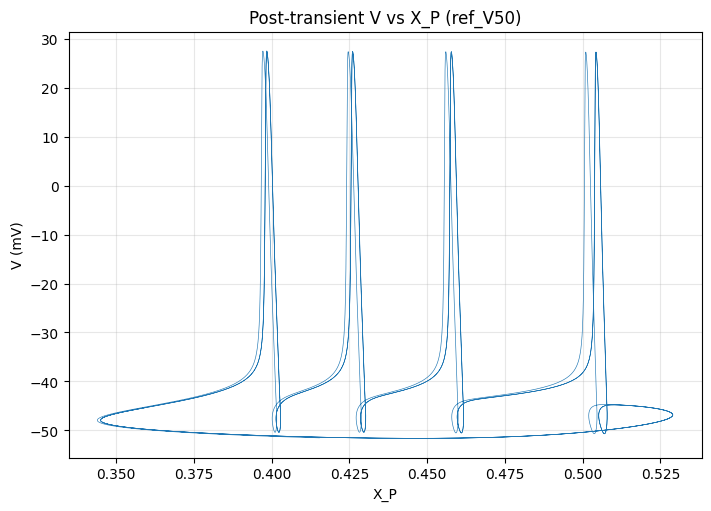

In [10]:
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
ax.plot(d['X_P'][m], V, lw=0.45)
ax.set_xlabel('X_P')
ax.set_ylabel('V (mV)')
ax.set_title('Post-transient V vs X_P (ref_V50)')
ax.grid(True, alpha=0.3)
fig.savefig(FIGDIR / 'phase_plane_V_XP.png', dpi=150)
plt.show()


## 13. Overall conclusion


In [11]:
print('Sections 1.4-1.5 notebook complete.')
print('- Untreated parameters unchanged; VODE only; model source not modified.')
print('- Robustness: compare summary table / PASS message above.')
print('- Phase planes: six-panel overview + enlarged V-X_P saved under', FIGDIR)


Sections 1.4-1.5 notebook complete.
- Untreated parameters unchanged; VODE only; model source not modified.
- Robustness: compare summary table / PASS message above.
- Phase planes: six-panel overview + enlarged V-X_P saved under /Users/calvinlai/Desktop/MATH3888/outputs/figures/robustness_phase_planes


## 14. Saved outputs


In [12]:
saved = sorted(FIGDIR.glob('*'))
print('Files in', FIGDIR)
for p in saved:
    print('  {:40s} {:8d} bytes'.format(p.name, p.stat().st_size))


Files in /Users/calvinlai/Desktop/MATH3888/outputs/figures/robustness_phase_planes
  phase_plane_V_XP.png                        76274 bytes
  phase_planes_six.png                       163645 bytes
  robustness_V_traces_ics.png                234923 bytes
  robustness_V_traces_tol.png                197980 bytes
  robustness_summary.csv                        508 bytes
